In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
from tabulate import tabulate

from umap import UMAP
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay, accuracy_score

import load.load_dataset as ds

import warnings
warnings.filterwarnings('ignore')
import joblib

In [10]:
param_dict = joblib.load(os.path.join(os.getcwd(), "parameters.joblib"))

# Prediction Accuracy

In [3]:
dataset_list = ['adult', 'bank', 'beans', 'heloc', 'ocean', 'wine'] # 'beans', 'cancer', 'mushroom',
models_list = ['model1', 'model1do1', 'model1bn' , 'model1r'] # , 'model1r'
models_colors = ['black', 'red', 'blue', 'green']

In [4]:
# test accuracy

acc_data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_true = y.argmax(dim=1).numpy()
    row = [d]
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            preds = model(X).argmax(dim=1).numpy()
        row.append(accuracy_score(y_true, preds))
    acc_data.append(row)

print('Test accuracy')
print(tabulate(acc_data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Test accuracy
| Dataset   |   model1 |   model1do1 |   model1bn |   model1r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.8360 |      0.8370 |     0.8250 |    0.8380 |
| bank      |   0.9080 |      0.9050 |     0.9140 |    0.9140 |
| beans     |   0.9120 |      0.9140 |     0.9120 |    0.9080 |
| heloc     |   0.7260 |      0.7140 |     0.6780 |    0.7060 |
| ocean     |   0.8298 |      0.8314 |     0.7749 |    0.7963 |
| wine      |   0.8550 |      0.8550 |     0.8650 |    0.8850 |


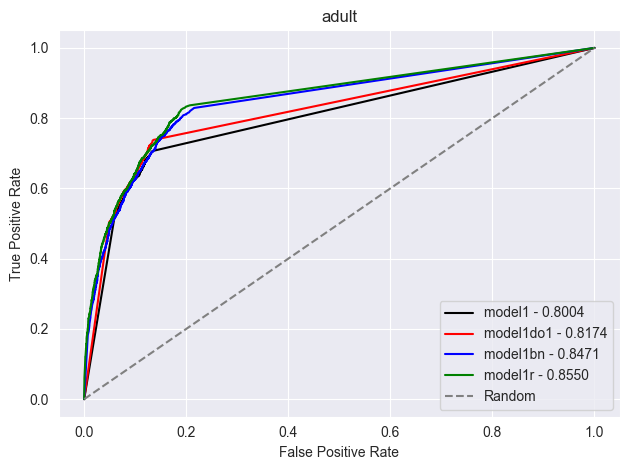

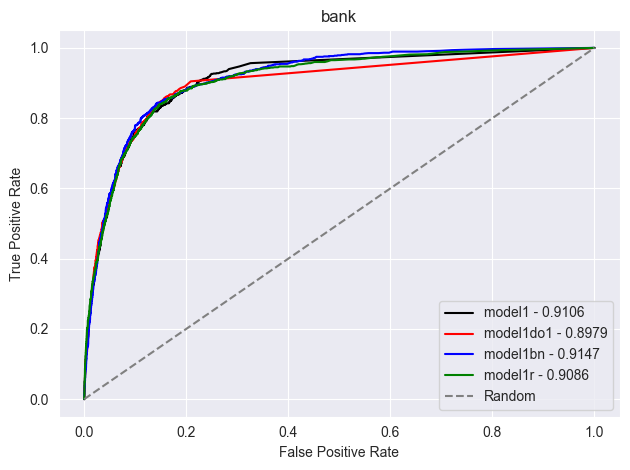

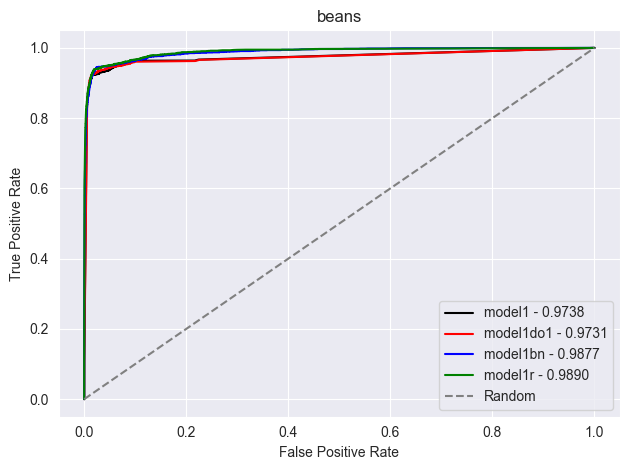

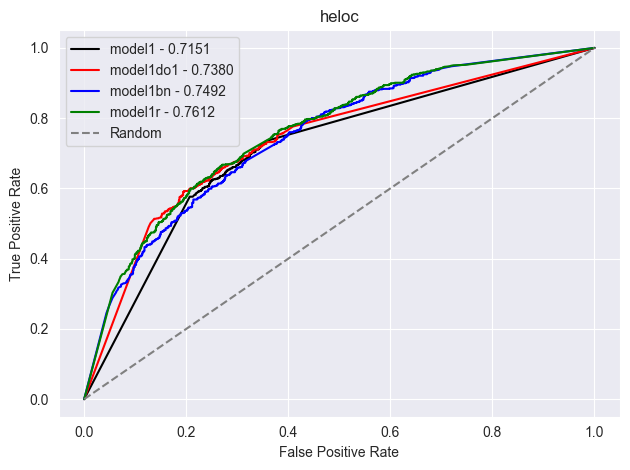

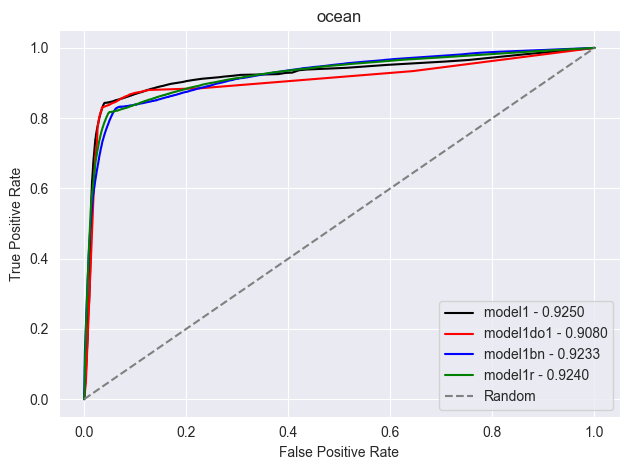

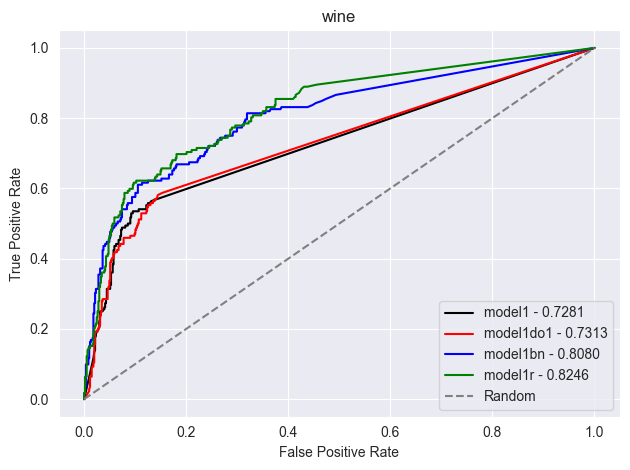

AUC score

| Dataset   |   model1 |   model1do1 |   model1bn |   model1r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.8004 |      0.8174 |     0.8471 |    0.8550 |
| bank      |   0.9106 |      0.8979 |     0.9147 |    0.9086 |
| beans     |   0.9738 |      0.9731 |     0.9877 |    0.9890 |
| heloc     |   0.7151 |      0.7380 |     0.7492 |    0.7612 |
| ocean     |   0.9250 |      0.9080 |     0.9233 |    0.9240 |
| wine      |   0.7281 |      0.7313 |     0.8080 |    0.8246 |


In [5]:
results = []
y_vals = []

for dataset in dataset_list:
    ddd = ds.Dataset(dataset)
    _, _, y_val = ddd.validation()
    y_vals.append(y_val)
    res = []
    for model in models_list:
        r = joblib.load(f'./models/results/{dataset}_{model}_results.joblib')
        res.append(r)
    results.append(res)

def ovr_roc(y_onehot, proba):
    if proba.shape[1] == 2:
        y, p = y_onehot[:, 1], proba[:, 1]
    else:
        y, p = y_onehot.ravel(), proba.ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), fpr, tpr

def plot_roc(y_val, results, dataset_name, models_colors, models_list):
    y_onehot = y_val.detach().numpy()
    auc_scores = []

    plt.figure()
    plt.title(dataset_name)
    for i in range(len(results)):
        roc, fpr, tpr = ovr_roc(y_onehot, results[i]['pred_proba'][0])
        plt.plot(fpr, tpr, color=models_colors[i], label=f'{models_list[i]} - {roc:.4f}')
        auc_scores.append(roc)

    plt.plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return auc_scores

auc_scores = []

# what to plot
#dataset_list = ["adult", "bank"]
for idx, dataset in enumerate(dataset_list):
    auc = plot_roc(y_vals[idx], results[idx], dataset, models_colors, models_list)
    auc_scores.append(auc)

print("AUC score\n")
auc_data = [[name, *scores] for name, scores in zip(dataset_list, auc_scores)]
headers = ["Dataset", *models_list]
print(tabulate(auc_data, headers=headers, tablefmt="github", floatfmt=".4f"))

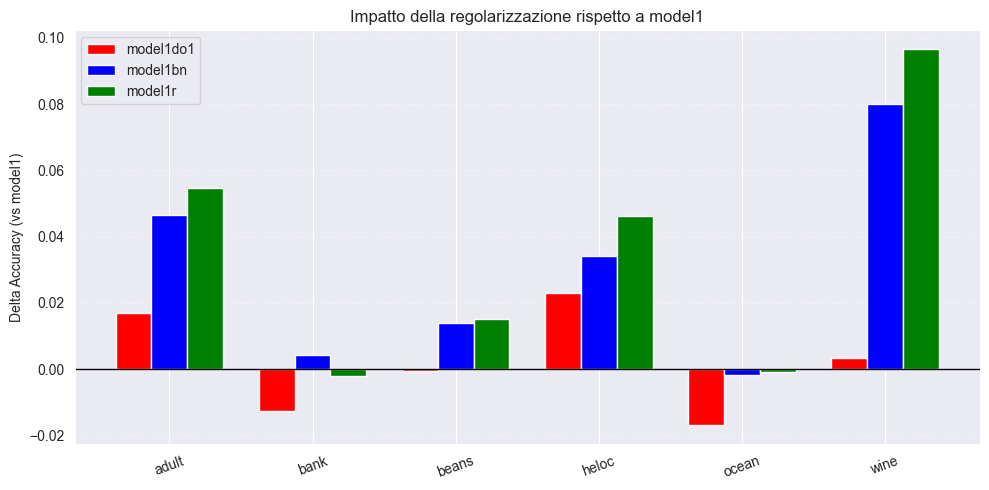

In [6]:
df = pd.DataFrame(auc_data, columns=headers)
reg_cols = models_list[1:]

baseline = models_list[0]
delta = df[reg_cols].sub(df[baseline], axis=0)
delta.index = df["Dataset"]

x = np.arange(len(delta.index))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(reg_cols):
  ax.bar(x + (i - 1) * width, delta[col], width, label=col, color=models_colors[i+1])

ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(delta.index, rotation=20)
ax.set_ylabel("Delta Accuracy (vs model1)")
ax.set_title("Impatto della regolarizzazione rispetto a model1")
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

# Regularization general: effect on robustness

Dropout slightly improve, BN worsen robustness


In [8]:
df_ens = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "my_originals", "ensemble_medoid_threshold.xlsx"))
df_do = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_do1.xlsx"))
df_bn = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_bn.xlsx"))
df_r = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_medoid_threshold_reg.xlsx"))

#df_mean = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc","mean_medoid_threshold_bn.xlsx"))
#df_ens_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "ensemble_random_threshold_bn.xlsx"))
#df_mean_random = pd.read_excel(os.path.join(os.getcwd(), "results_roc_auc", "mean_random_threshold_bn.xlsx"))

param_dict = joblib.load(os.path.join(os.getcwd(), "parameters.joblib"))

In [28]:
# Table 1

model_name = "model1"
df_e_t1 = df_ens[np.isclose(df_ens["threshold"], 0.80) & df_ens["model"].isin([model_name])].copy()
df_e_t1["rob_%"] = 100 * df_e_t1["robust"] / df_e_t1["len"]
df_e_t1["maybe_%"] = 100 * df_e_t1["maybe"] / df_e_t1["len"]
df_e_t1["non_rob_%"] = 100 * df_e_t1["non robust"] / df_e_t1["len"]
df_e_t1 = df_e_t1.set_index("dataset")[["rob_%", "maybe_%", "non_rob_%"]]

model_do = f"{model_name}do1"
df_do_t1 = df_do[np.isclose(df_do["threshold"], 0.80) & df_do["model"].isin([model_do])].copy()
df_do_t1["rob_%"] = 100 * df_do_t1["robust"] / df_do_t1["len"]
df_do_t1["maybe_%"] = 100 * df_do_t1["maybe"] / df_do_t1["len"]
df_do_t1["non_rob_%"] = 100 * df_do_t1["non robust"] / df_do_t1["len"]
df_do_t1 = df_do_t1.set_index("dataset")[["len", "rob_%", "maybe_%", "non_rob_%"]]

model_bn = f"{model_name}bn"
df_bn_t1 = df_bn[np.isclose(df_bn["threshold"], 0.80) & df_bn["model"].isin([model_bn])].copy()
df_bn_t1["rob_%"] = 100 * df_bn_t1["robust"] / df_bn_t1["len"]
df_bn_t1["maybe_%"] = 100 * df_bn_t1["maybe"] / df_bn_t1["len"]
df_bn_t1["non_rob_%"] = 100 * df_bn_t1["non robust"] / df_bn_t1["len"]
df_bn_t1 = df_bn_t1.set_index("dataset")[["rob_%", "maybe_%", "non_rob_%"]]


table1 = df_do_t1.join(df_e_t1, lsuffix="_ens", rsuffix="_mean").join(df_bn_t1, lsuffix="_ens", rsuffix="_mean")
table1 = table1.round(1)

table1.columns = pd.MultiIndex.from_tuples([
    ("", "Dtest"),
    ("Dropout", "Robust"),
    ("Dropout", "Uncertain"),
    ("Dropout", "Non Robust"),
    (model_name, "Robust"),
    (model_name, "Uncertain"),
    (model_name, "Non Robust"),
    ("BatchNorm", "Robust"),
    ("BatchNorm", "Uncertain"),
    ("BatchNorm", "Non Robust"),
])

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
table1.index.name = None
table1.columns.names = [None, None]
display(table1)

In [13]:
# Table 1 ma solo robust

model_name = "model1"
df_e_t1 = df_ens[np.isclose(df_ens["threshold"], 0.80) & df_ens["model"].isin([model_name])].copy()
df_e_t1["rob_%"] = 100 * df_e_t1["robust"] / df_e_t1["len"]
df_e_t1 = df_e_t1.set_index("dataset")[["rob_%"]]

model_do = f"{model_name}do1"
df_do_t1 = df_do[np.isclose(df_do["threshold"], 0.80) & df_do["model"].isin([model_do])].copy()
df_do_t1["rob_%"] = 100 * df_do_t1["robust"] / df_do_t1["len"]
df_do_t1 = df_do_t1.set_index("dataset")[["rob_%"]]

model_bn = f"{model_name}bn"
df_bn_t1 = df_bn[np.isclose(df_bn["threshold"], 0.80) & df_bn["model"].isin([model_bn])].copy()
df_bn_t1["rob_%"] = 100 * df_bn_t1["robust"] / df_bn_t1["len"]
df_bn_t1 = df_bn_t1.set_index("dataset")[["rob_%"]]

model_r = f"{model_name}r"
df_r_t1 = df_r[np.isclose(df_r["threshold"], 0.80) & df_r["model"].isin([model_r])].copy()
df_r_t1["rob_%"] = 100 * df_r_t1["robust"] / df_r_t1["len"]
df_r_t1 = df_r_t1.set_index("dataset")[["rob_%"]]


table1 = df_do_t1.join(df_e_t1, lsuffix="_a", rsuffix="_b").join(df_bn_t1, lsuffix="_c", rsuffix="_d").join(df_r_t1, lsuffix="_e", rsuffix="_f")
table1 = table1.round(1)

table1.columns = pd.MultiIndex.from_tuples([
    ("Dropout", "Robust"),
    (model_name, "Robust"),
    ("BatchNorm", "Robust"),
    ("BN+Dropout", "Robust")
])

table1 = table1.reindex([d for d in param_dict.keys() if d in table1.index])
table1.index.name = None
table1.columns.names = [None, None]
display(table1)

,Dropout,model1,BatchNorm,BN+Dropout
,Robust,Robust,Robust,Robust
adult,79.3,73.2,18.5,57.7
bank,69.5,67.0,5.6,22.5
beans,77.8,75.6,95.6,97.4
cancer,72.0,78.0,48.0,64.0
heloc,13.8,26.4,12.2,25.4
mushroom,26.0,8.0,4.8,19.0
ocean,79.4,76.8,83.9,86.8
wine,3.5,2.0,7.5,29.0


# Dataset specific plots

- bank robustness worsen with BN, show attribution vector of bank
- regularization worsen heloc robustness, understand why
- regularization improve wine robustness, understand why

#### adult

#### bank

we can see how adding BN in bank reduce the robustness score, upon further analysis it can be seen that the attribution vectors of regularized models of bank have a lower variance compared to the non regularized models. <br><br>
HYPOTHESIS: this is because the regularization move the decision boundary of the model toward a space where smaller variation and noise count against the correct prediction, MAYBE BECAUSE BANK IS A DATASET WHERE A MORE OVERFITTED DECISION BOUNDARY MAKES BETTER PREDICTIONS

In [10]:
model_list = ['model1'] # , 'model2', 'model3' TODO scaricare gli altri modelli e aggiungerli qui
dataset_name = "bank"

neigh = "medoid" # medoid random
set_type = "test" # validation test

folder = os.path.join(os.getcwd(), f"results_{neigh}")

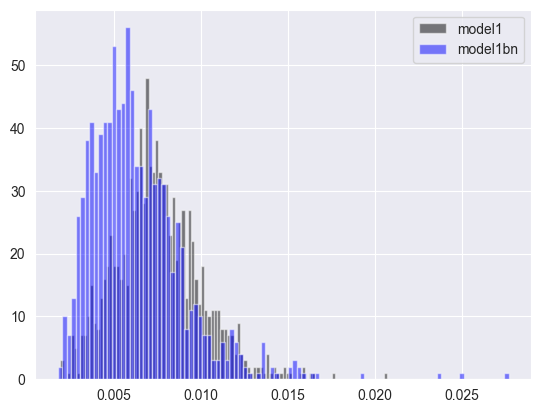

In [11]:
def compute_variances(folder, model_name, compare_with, dataset_name, set_type):
    variance_vec = []

    folder_ = os.path.join(folder, f"{dataset_name}_{model_name}")
    folder_reg = os.path.join(folder, f"{dataset_name}_{model_name}{compare_with}")

    # FOR ENSEMBLE
    """att_m = np.load(os.path.join(folder_, f"{set_type}", "ensemble.npy"))
    att_reg = np.load(os.path.join(folder_reg, f"{set_type}", "ensemble.npy"))
    att_m = att_m[:, 0, :]
    att_reg = att_reg[:, 0, :]"""

    # FOR SINGLE METHOD ATTRIBUTIONS
    # 0:IG, 1:DL, 2:LRP
    att_m = np.load(os.path.join(folder_, f"{set_type}", "attributions.npy"))
    att_reg = np.load(os.path.join(folder_reg, f"{set_type}", "attributions.npy"))
    att_m = att_m[:, 0, :, 1]
    att_reg = att_reg[:, 0, :, 1]

    att_m = np.abs(att_m)
    att_m = att_m / att_m.sum(axis=1, keepdims=True)
    variance_m = att_m.var(axis=1)

    att_reg = np.abs(att_reg)
    att_reg = att_reg / att_reg.sum(axis=1, keepdims=True)
    variance_reg = att_reg.var(axis=1)

    variance_vec.append([variance_m, variance_reg])
    return np.array(variance_vec).squeeze()

for model_name in model_list:
    variance_m, variance_bn = compute_variances(folder, model_name, 'bn', dataset_name, set_type)
    plt.hist(variance_m, bins=100, alpha=0.5, label=f"{model_name}", color="black")
    plt.hist(variance_bn, bins=100, alpha=0.5, label=f"{model_name}bn", color="blue")
    plt.legend(); plt.show()

#### heloc

#### ocean

# MAPPA cambiamento

In [24]:
def plot_map(dataset_name, model_name, neigh = "medoid", agg = "ensemble"):
    folder = os.path.join(os.getcwd(), f"results_{neigh}")
    dataset = ds.Dataset(dataset_name)
    X_val_or, X_val, y_val = dataset.validation()
    X_test_or, X_test, y_test = dataset.test()

    th = 0.80
    k_r = param_dict[dataset_name][f"{agg}_{neigh}_k"]

    folder_ = os.path.join(folder, f"{dataset_name}_{model_name}")
    rho_valid = np.nan_to_num(np.load(os.path.join(folder_, "validation", f"robustness_{agg}_{neigh}.npy")))
    rho_test = np.load(os.path.join(folder_, "test", f"robustness_{agg}_{neigh}.npy"))

    rob_hat = KNeighborsRegressor(n_neighbors=k_r).fit(X_val_or, rho_valid[:,3]).predict(X_test_or)
    rob_ = rho_test[:,3]

    labels = np.full(len(rob_), "Non Robust", dtype=object)
    labels[(rob_ >= th) & (rob_hat < th)] = "Uncertain"
    labels[(rob_ >= th) & (rob_hat >= th)] = "Robust"

    umap = UMAP(n_components=2, random_state=0, n_jobs=1)
    X_new = umap.fit_transform(X_test_or)

    palette = {"Robust": "tab:blue", "Uncertain": "tab:green", "Non Robust": "tab:orange"}

    plt.figure(figsize=(8,6))
    for lab, col in palette.items():
        m = labels == lab
        plt.scatter(X_new[m,0], X_new[m,1], c=col, s=50, label=f"{lab} ({100*m.mean():.1f}%)")
    plt.title(f"UMAP projections Robustness coloring: {dataset_name} {model_name} ({agg} {neigh})")
    plt.xlabel("$P_1$")
    plt.ylabel("$P_2$")
    plt.legend()
    plt.show()

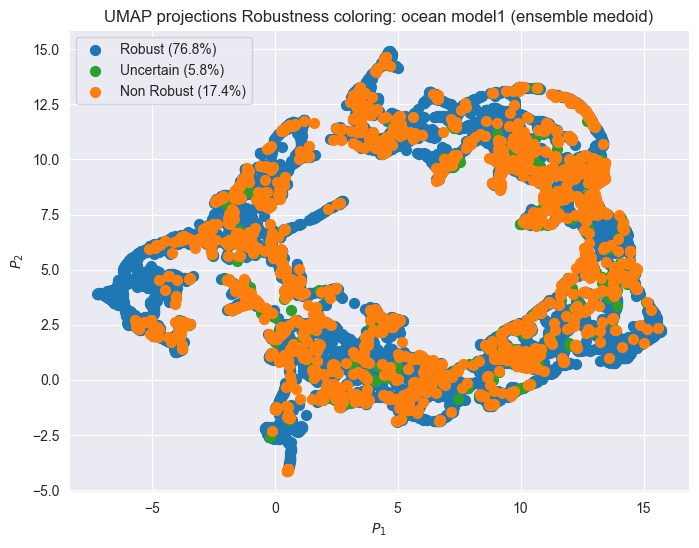

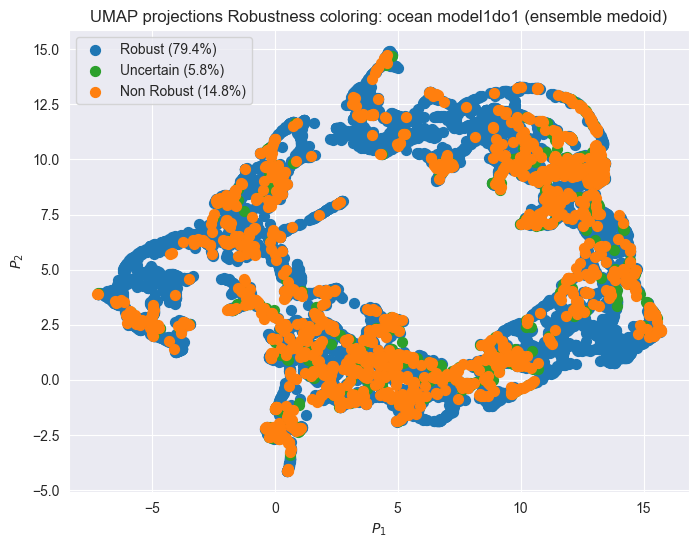

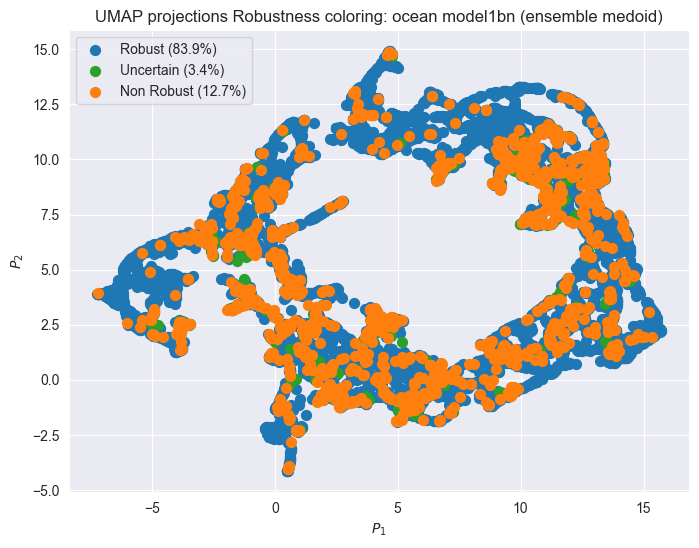

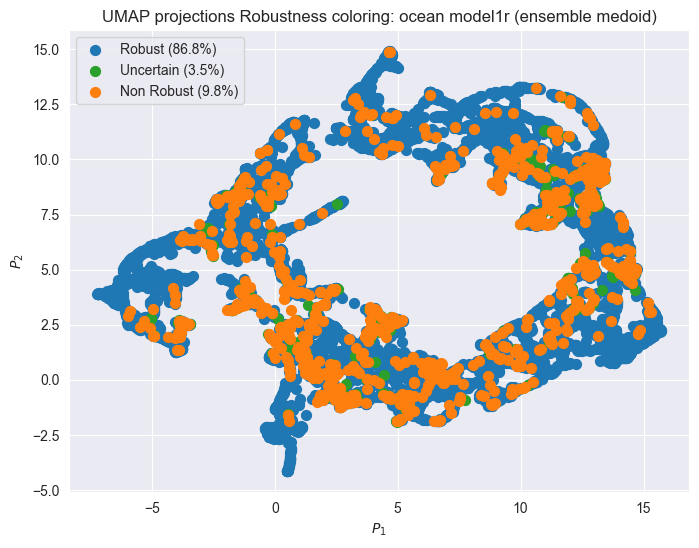

In [26]:
dataset_name = "ocean"
plot_map(dataset_name, "model1")
plot_map(dataset_name, "model1do1")
plot_map(dataset_name, "model1bn")
plot_map(dataset_name, "model1r")